# Projet Deep learning - CNN pour panneaux de signalisation

## Partie 1 - Présentation et traitement du dataset.

### Description du Dataset
Pour ce projet, nous allons utiliser le dataset GTSRB -German Traffics Signs Recognition Benchmark-. Voici ses informations :
- Auteur : Mykola
- License : CC0: Public Domain
- Taille dataset entrainement : 39209 images de panneaux (dans le répertoire d'entrainement)
- Taille dataset Test : 12630 images
- Nombre de classes: 43

### Description classes
Voici les différentes classes et leurs signification, ainsi que la quantité d'images par classe :


In [1]:
from pathlib import Path
import pandas as pd
import trafficsigns.data.observe_dataset as obs
from trafficsigns.config import ROOT

correspondance = {
    0: "Limite de vitesse (20 km/h)",
    1: "Limite de vitesse (30 km/h)",
    2: "Limite de vitesse (50 km/h)",
    3: "Limite de vitesse (60 km/h)",
    4: "Limite de vitesse (70 km/h)",
    5: "Limite de vitesse (80 km/h)",
    6: "Fin de limitation de vitesse (80 km/h)",
    7: "Limite de vitesse (100 km/h)",
    8: "Limite de vitesse (120 km/h)",
    9: "Interdiction de dépasser",
    10: "Interdiction de dépasser pour les véhicules > 3.5 t",
    11: "Interdiction d'intersection / Priorité à la prochaine intersection",
    12: "Route prioritaire",
    13: "Cédez le passage",
    14: "Stop",
    15: "Circulation interdite à tout véhicule dans les deux sens",
    16: "Interdiction d'accès aux véhicules > 3.5 t",
    17: "Sens interdit",
    18: "Danger",
    19: "Virage à gauche",
    20: "Virage à droite",
    21: "Successions de virages",
    22: "Casserole / Route bosselée",
    23: "Chaussée glissante",
    24: "Rétrécissement de la chaussée par la droite",
    25: "Travaux en cours",
    26: "Signaux lumineux / Feux tricolores",
    27: "Passage de piétons",
    28: "Attention enfants",
    29: "Passage de cyclistes",
    30: "Danger neige / verglas",
    31: "Passage d'animaux sauvages",
    32: "Fin de toutes les interdictions précédemment signalées",
    33: "Obligation de tourner à droite",
    34: "Obligation de tourner à gauche",
    35: "Obligation d'aller tout droit",
    36: "Obligation d'aller tout droit ou à droite",
    37: "Obligation d'aller tout droit ou à gauche",
    38: "Contournement obligatoire par la droite",
    39: "Contournement obligatoire par la gauche",
    40: "Rond-point",
    41: "Fin d'interdiction de dépasser",
    42: "Fin d'interdiction de dépasser pour les véhicules > 3.5 t",
}

print("== Quantités de chaque classe du dataset d'entrainement ==")

PATH_TO_FILES = Path.joinpath(ROOT, "data", "raw", "gtsrb")

data_frame = pd.read_csv(filepath_or_buffer=Path.joinpath(PATH_TO_FILES, "Train.csv"))

quantity_frame = obs.get_quantity_of_class(data_frame, "ClassId")

# 1. Mappage des IDs vers les libellés des panneaux
quantity_frame["Panneau"] = quantity_frame["ClassID"].map(correspondance)

# 2. Réorganisation des colonnes pour placer le libellé à côté de l'ID
quantity_frame = quantity_frame[["ClassID", "Panneau", "Quantité"]]

print(quantity_frame)
print(f"Nombre de classes : {len(quantity_frame)}")

== Quantités de chaque classe du dataset d'entrainement ==
    ClassID                                            Panneau  Quantité
0        20                                    Virage à droite       360
1         0                        Limite de vitesse (20 km/h)       210
2         1                        Limite de vitesse (30 km/h)      2220
3         2                        Limite de vitesse (50 km/h)      2250
4         3                        Limite de vitesse (60 km/h)      1410
5         4                        Limite de vitesse (70 km/h)      1980
6         5                        Limite de vitesse (80 km/h)      1860
7         6             Fin de limitation de vitesse (80 km/h)       420
8         7                       Limite de vitesse (100 km/h)      1440
9         8                       Limite de vitesse (120 km/h)      1410
10        9                           Interdiction de dépasser      1470
11       10  Interdiction de dépasser pour les véhicules > ...   

## Dimension des images

Les images ne sont pas toutes de la même taille. La taille s'étend de (25,25)px à (225,243)px avec une médiane de 43px. Nous avons décidé de prendre la puissance de 2 la plus proche de la médiane, c'est-à-dire (32,32)px.

== Informations sur la taille des images ==
         Hauteur  Largeur
Minimum     25.0     25.0
Median      43.0     43.0
Maximum    225.0    243.0


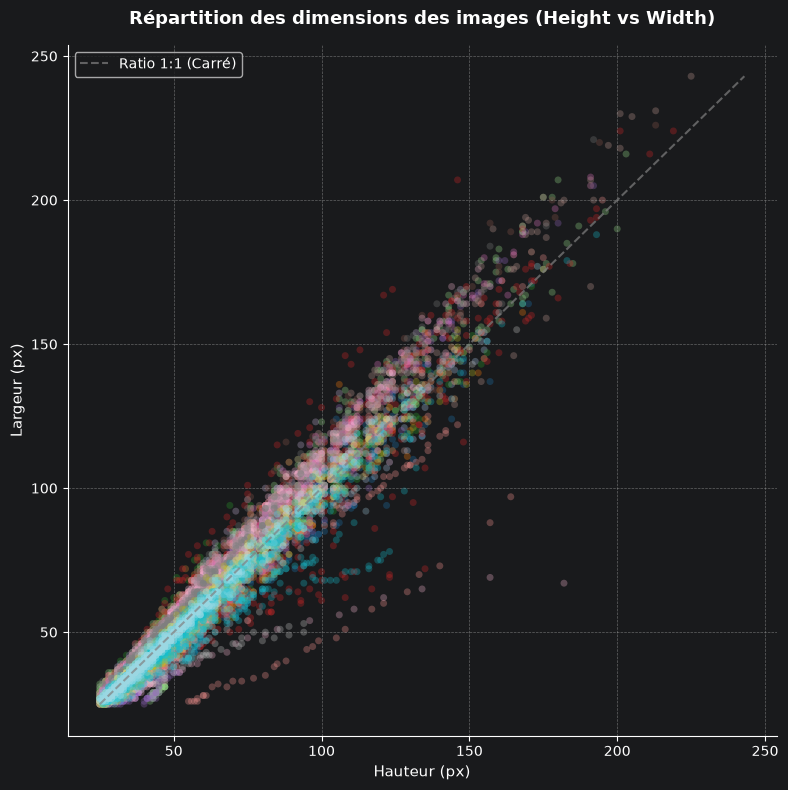

In [2]:
import numpy as np
print("== Informations sur la taille des images ==")

size_dataframe = pd.DataFrame({"Hauteur" : [data_frame['Height'].min(), np.median(np.array(data_frame['Height'])), data_frame['Height'].max()], "Largeur" : [data_frame['Width'].min(), np.median(np.array(data_frame['Width'])), data_frame['Width'].max()]}, index=["Minimum", "Median", "Maximum"])
print(size_dataframe)

obs.get_size_of_images_plot(data_frame)


## Format des images

- ".png" seulement
- 3 channels (RGB)
- 24 bits de profondeur

Toutes les images on exactement le même format, ce qui permet de les charger plus rapidement et de les traiter plus efficacement. (évite la création d'une classe de conversion de format)